<IPython.core.display.Javascript object>

<function matplotlib.pyplot.show(close=None, block=None)>

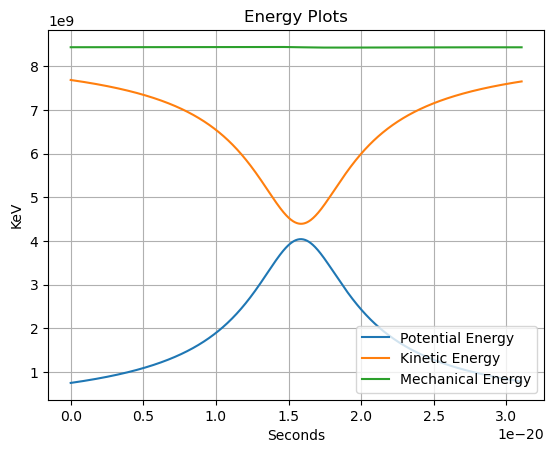

In [6]:
import vpython as vp
import matplotlib.pyplot as plt

scene = vp.canvas()

alphaMass = (6.6)*10**(-27) #kg
e = (1.6)*10**(-19) #Coulombs
Qalpha = 2*e #coulombs
Qgold = 79*e #coulombs
fm = 10**(-15) #meter / fermi
Ralpha = (1.2*fm) *(4**(1/3))
Rgold = (1.2*fm) * (192**(1/3))
MeV = (1.6)*10**(-13) # Joules


x = 300*fm #fermi
y = 30*fm
z = -30*fm

vx = ((2*7.7*MeV)/alphaMass)**(1/2)
vy = 0
vz = 0
v = vp.vector(-vx, vy,vz)

t = 0
tMax = (600*fm)/vx
dt = 0.001*tMax

alpha = vp.sphere(pos = vp.vector(x,y,z), radius = Ralpha, color = vp.color.green, make_trail = True)
gold = vp.sphere(pos = vp.vector(0,0,0), radius = Rgold , color = vp.color.yellow)

ulist = []
klist = []
elist = []
tlist = []


while t < tMax:
    vp.rate(100)
    Fnet =  8.987551788e9*(Qalpha*Qgold)/(alpha.pos.mag2)*alpha.pos.hat
    a = Fnet/alphaMass
    v = v + a*dt
    alpha.pos = alpha.pos + v*dt
    
    u =  8.987551788e9*(Qalpha*Qgold)/(alpha.pos.mag) * 6.2415e21
    ulist.append(u)

    k = 0.5 *alphaMass * (v.mag2) * 6.2415e21
    klist.append(k)

    e = u+k
    elist.append(e)
    
    tlist.append(t)
    t = t+dt
    


plt.grid()
plt.title('Energy Plots')
plt.ylabel('KeV')
plt.xlabel('Seconds')
plt.plot(tlist,ulist)
plt.plot(tlist,klist)
plt.plot(tlist,elist)

'''
plt.figure()
plt.plot(tlist,elist)
'''
plt.legend(["Potential Energy", "Kinetic Energy","Mechanical Energy"], loc="lower right")

plt.show


